# Task 2.4: from the readout trade-off to enlarge, measure, restore

The argument is: **derive the controls → measure the fixed-size trade-off → choose enlargement → test the complete cycle**. Static logical relaxation and recovered wrong-state population are separate tests. Speed is compared with the specified weak readout at a common signal target; the readout-stage rate is compared with original undriven storage.

This notebook reconstructs saved evidence without another quantum campaign. Detailed circuit corrections, alternative controls and numerical methods are supporting appendices. The full-cycle result uses the ideal cubic model; the signal benchmark is not measured single-shot fidelity.

In [1]:
from pathlib import Path
import sys, json, re, importlib.util
import numpy as np
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT/'results/task_2_4.json').is_file():
    ROOT = ROOT.parent
assert (ROOT/'results/task_2_4.json').is_file()
sys.path.insert(0, str(ROOT))
spec = importlib.util.spec_from_file_location('final_synthesis', ROOT/'tools/synthesize_task_2_4.py')
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)
summary = json.loads(module.build().read_text())
local = json.loads((ROOT/'results/task_2_4.json').read_text())
report = (ROOT/'docs/task_2_4_final.md').read_text()
def report_section(start, end):
    text = report[report.index(start):report.index(end)]
    text = re.sub(r'!\[[^\n]*\]\([^\n]*\)(?:\{[^\n]*\})?', '', text)
    text = re.sub(r'\\Needspace\{[^\n]*\}', '', text)
    return text.strip()
print('Recomputed raw-trajectory information and recovered logical populations.')
print('Verified frozen cloud source records:', summary['frozen_cloud_source_records_verified'])
print('Indexed input files:', len(summary['source_files_sha256']))

Recomputed raw-trajectory information and recovered logical populations.
Verified frozen cloud source records: 66
Indexed input files: 120


In [2]:
display(Markdown(report_section('# Task 2.4(a):', '# Task 2.4(b):')))

# Task 2.4(a): derive the readout Hamiltonian

## Pumped circuit and two-photon exchange

With $\hbar=1$, the circuit Hamiltonian is

$$
H_{\rm circuit}=\omega_a a^\dagger a+\omega_b b^\dagger b
-2E_J\cos\varphi_\Sigma\cos(\hat\varphi+\varphi_\Delta),\qquad
\hat\varphi=\varphi_a(a+a^\dagger)+\varphi_b(b+b^\dagger).
$$

The operators $a$ and $b$ annihilate memory and buffer photons; $\varphi_a$ and $\varphi_b$ are their zero-point phases. At $\varphi_\Delta=\pi/2$ and $\varphi_\Sigma=-\pi/2+\epsilon_p\cos\omega_pt$, the identities $\cos(\hat\varphi+\pi/2)=-\sin\hat\varphi$ and $\cos\varphi_\Sigma\simeq\epsilon_p\cos\omega_pt$ give

$$
H_{\rm ATS}(t)\simeq2E_J\epsilon_p\cos\omega_pt
\left(\hat\varphi-\frac{\hat\varphi^3}{6}+\frac{\hat\varphi^5}{120}+\cdots\right).
$$

The mixed cubic contribution is

$$
H_{\rm ATS}^{(3)}\supset-E_J\epsilon_p\varphi_a^2\varphi_b\cos\omega_pt
(a+a^\dagger)^2(b+b^\dagger).
$$

Here $(a+a^\dagger)^2=a^2+a^{\dagger2}+2a^\dagger a+1$. In the rotating frame, $a^2b^\dagger$ acquires $e^{-i(2\omega_a-\omega_b)t}$. Choosing $\omega_p=2\omega_a-\omega_b$ cancels that rotation through one pump harmonic. The factor $1/2$ from the cosine gives

$$
H_{\rm ex}=g_2(a^2b^\dagger+a^{\dagger2}b),\qquad
|g_2|=\frac{E_J\epsilon_p\varphi_a^2\varphi_b}{2}.
$$

This pump phase gives negative exchange. We shift it by $\pi$ and use $g_2>0$ throughout. For $(\omega_a,\omega_b,\omega_p)/2\pi=(4.0,4.8,3.2)$ GHz, $E_J/2\pi=40$ GHz, $\varphi_a=0.06$ and $\varphi_b=0.30$, the rounded $\epsilon_p=0.035$ gives $|g_2|/2\pi=0.756$ MHz. Using $\epsilon_p=0.0353241$ gives the specified 0.763 MHz. These are illustrative circuit parameters [1,3].

## Separate microwave drives

The flux pump creates the exchange interaction. A separate resonant buffer microwave supplies $H_d=-\epsilon_d(b+b^\dagger)$ and sets $\alpha^2=\epsilon_d/g_2$. A further memory microwave port supplies the readout force. With the explicit laboratory phase convention

$$
H_{Z,\rm lab}=2\epsilon_Z(t)\cos(\omega_at-\phi)(a+a^\dagger),
$$

the resonant rotating-frame term is $H_Z=\epsilon_Z(t)(e^{i\phi}a^\dagger+e^{-i\phi}a)$. The discarded terms rotate at $2\omega_a$. A charge-coupled port realizes the same convention after a carrier-phase choice. All main calculations use $\phi=0$, giving

$$
\boxed{H=g_2(a^2b^\dagger+a^{\dagger2}b)-\epsilon_d(b+b^\dagger)
+\epsilon_Z(t)(a+a^\dagger).}
$$

The memory drive is therefore an explicitly added physical control, rather than an automatic consequence of the specified ATS pump.

## Corrections to the leading interaction

The first-order linear terms are off resonance at the supplied frequencies. Keeping the resonant exchange through fifth order gives

$$
\begin{aligned}
H_{\rm ex}^{(\le5)}={}&g_2[1-(\varphi_a^2+\varphi_b^2)/2]a^2b^\dagger\\
&-\frac{g_2\varphi_a^2}{3}a^\dagger a^3b^\dagger
-\frac{g_2\varphi_b^2}{2}a^2b^{\dagger2}b+\mathrm{h.c.}
\end{aligned}
$$

The last two terms still exchange two memory photons for one buffer photon, but their amplitudes depend on occupation. The first term includes the associated correction to the cubic coefficient. An odd sine potential gives no static Kerr term at first pump order. Off-resonant processes can generate frequency shifts and Kerr interactions at second pump order; those are effective corrections, not terms retained directly by the first-order rotating-wave approximation. Appendix A derives and tests these corrections. The numerical protocol below uses the leading cubic model: the buffer drive controls cat size, and the memory drive produces the readout signal.

# Task 2.4(b): establish the contrast-error trade-off

## Model and weak-drive response

We solve both modes, with time in µs and angular frequencies in $\mathrm{µs}^{-1}$:

$$
\dot\rho=-i[H,\rho]+\kappa_a\mathcal D[a]\rho+\kappa_b\mathcal D[b]\rho,
\qquad\mathcal D[c]\rho=c\rho c^\dagger-\tfrac12\{c^\dagger c,\rho\}.
$$

The supplied values are $g_2/2\pi=0.763$ MHz, $\kappa_b/2\pi=2.6$ MHz and $\kappa_a/2\pi=9.3$ kHz, with storage amplitude $\alpha=2.1$. Because $g_2/\kappa_b=0.2935$ and $\epsilon_d/\kappa_b=1.2942$, eliminating the buffer is not uniformly justified. Each simulation starts separately in $|+\alpha\rangle_a|0\rangle_b$ or $|-\alpha\rangle_a|0\rangle_b$.

For $A=\langle a\rangle$ and $B=\langle b\rangle$, factorization gives

$$
\dot A=-2ig_2A^*B-i\epsilon_Z-\kappa_a A/2,\qquad
\dot B=-i(g_2A^2-\epsilon_d)-\kappa_bB/2.
$$

Without memory loss or readout, $A=\pm\alpha$ and $B=0$: the buffer drive and conversion amplitude cancel. The readout force first moves the memory in its imaginary direction and disturbs that cancellation. Linearize around $A=s\alpha+\delta A$, $s=\pm1$. Neglecting loss and quadratic deviations, the settled memory equation is $0=-2ig_2s\alpha B_s-i\epsilon_Z$, hence

$$
\boxed{B_s\simeq-s\frac{\epsilon_Z}{2\alpha g_2},\qquad
C_b\equiv|B_+-B_-|\simeq\frac{|\epsilon_Z|}{\alpha g_2}.}
$$

The buffer fields have opposite real signs. This weak-drive approximation applies after fast settling and before switching erases the initial-bit signal; the driven memory need not remain exactly at $\pm\alpha$.

Output distinguishability dephases a superposition, even without switching its bit. Unwanted switching is a separate process: drive-induced excitation can relax into the opposite logical branch.

## Increasing the drive at fixed cat size

Here $\Gamma_X$ is the logical population-imbalance decay exponent; a symmetric one-way switching rate is $\Gamma_X/2$. We estimate it from the Lindblad generator and check it against time evolution where decay is resolvable (Appendix B).

At $\alpha=2.1$, the executed two-mode sweep gives:

| $\epsilon_Z/g_2$ | Real-field contrast $C_b$ | $\Gamma_X$ ($\mathrm{µs}^{-1}$) |
|--:|--:|--:|
| 0.05 | 0.02379 | $6.12\times10^{-6}$ |
| 0.10 | 0.04757 | $2.37\times10^{-5}$ |
| 0.25 | 0.11885 | $1.62\times10^{-4}$ |
| 0.50 | 0.23689 | $9.24\times10^{-4}$ |
| 1.00 | 0.46037 | $8.61\times10^{-3}$ |

Over this sweep, a stronger drive produces a larger signal and a larger switching rate. These are static rates: they do not by themselves determine the error of a shorter measurement. A finite protocol must also be tested through its complete return and recovery.

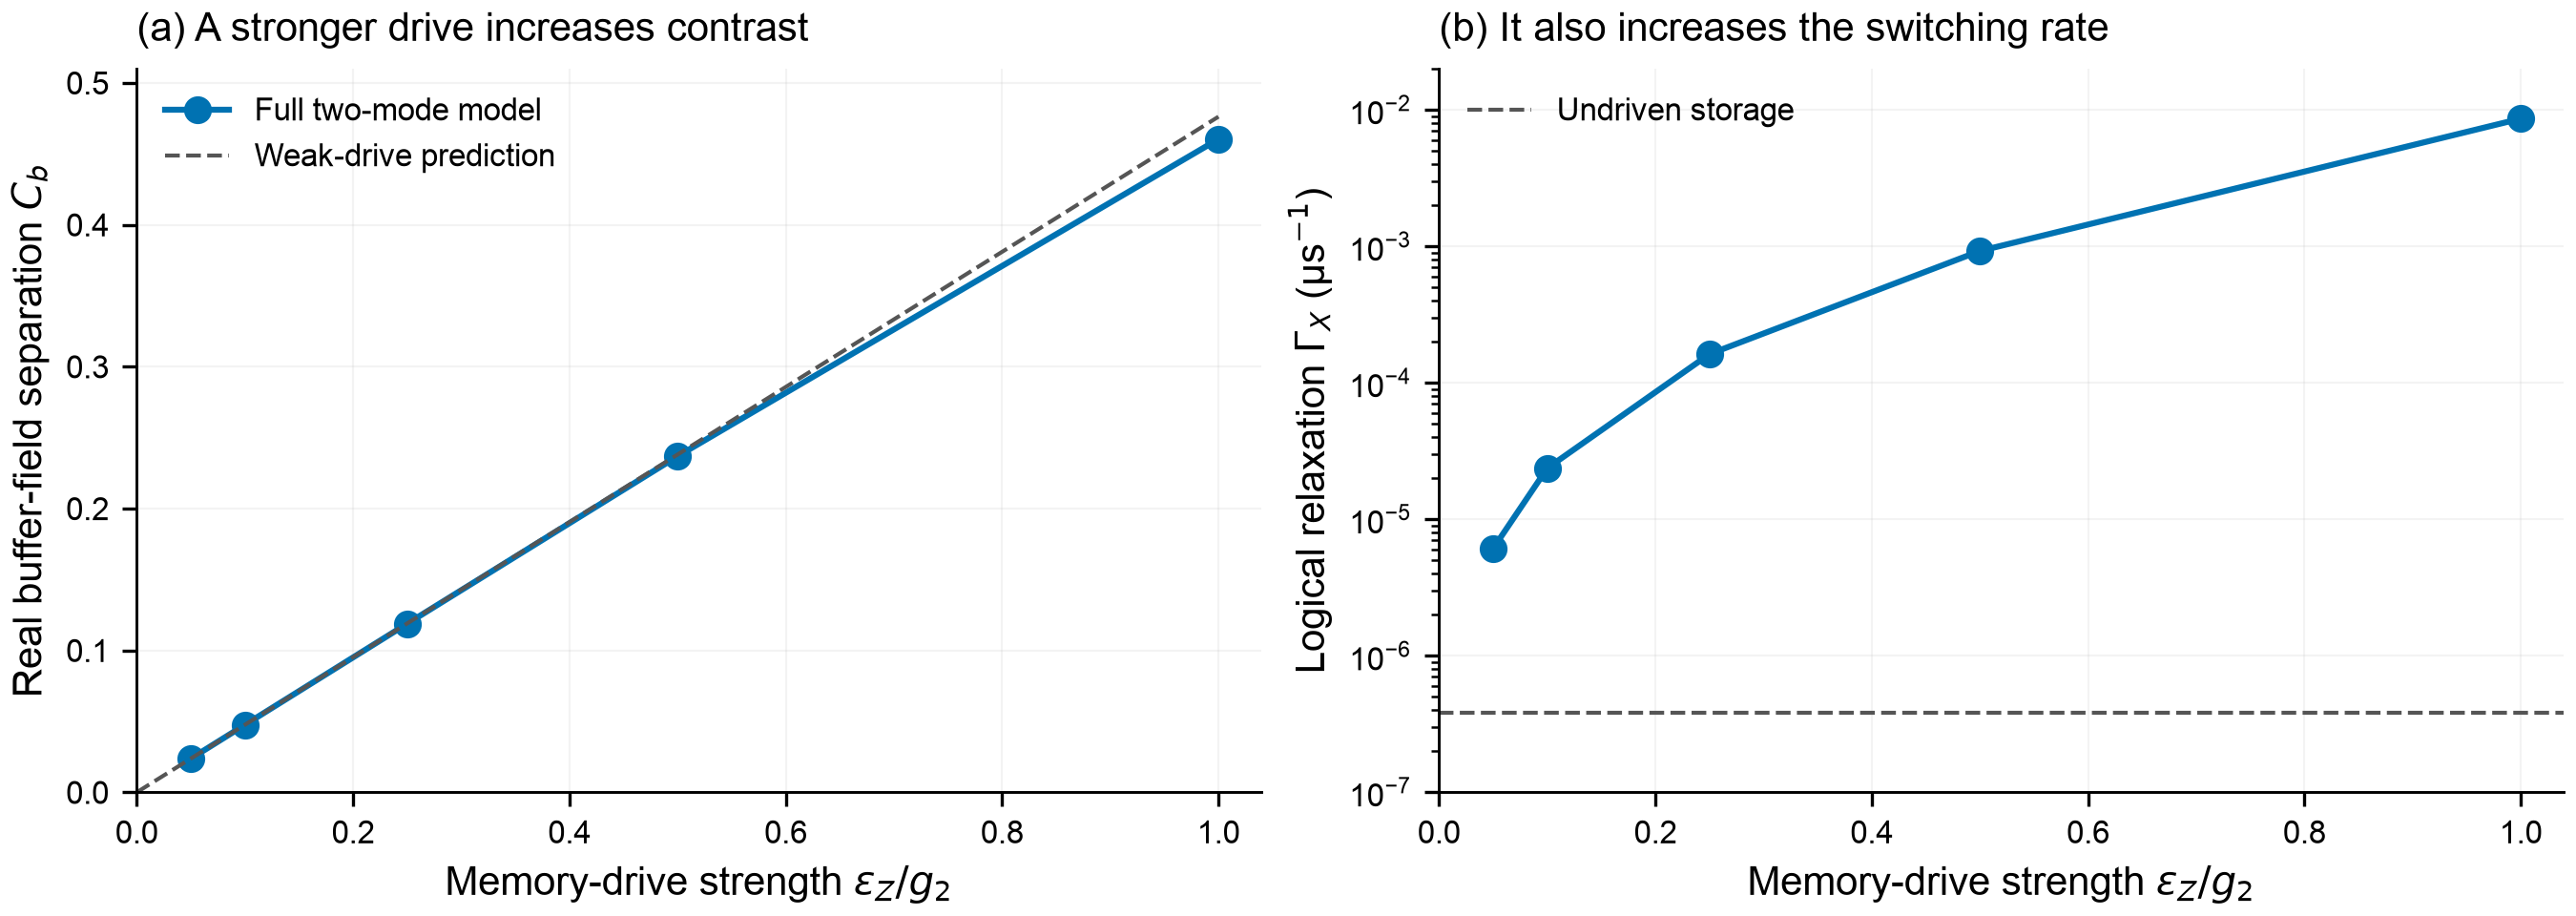

In [3]:
display(Markdown(report_section('# Task 2.4(b):', '# Task 2.4(c):')))
display(Image(filename=str(ROOT/'figures/task_2_4_drive_tradeoff.png'), width=900))

# Task 2.4(c): propose and demonstrate one protocol

## Objective and comparison

The fixed-size sweep suggests changing the protection during readout, rather than only increasing the force. Larger cat separation suppresses switching [2], but reduces the weak-drive response as $1/\alpha$. We therefore test a larger cat with a stronger drive: $\alpha=2.6$ and $\epsilon_Z=0.1g_2$.

The objective is a shorter complete cycle at a common signal target, with the estimated readout-stage $\Gamma_X$ no larger than **undriven storage at $\alpha=2.1$**. Speed is compared with the specified **weak readout at $\alpha=2.1$ and $\epsilon_Z=0.05g_2$**.

For the model's opposite real buffer responses, use ideal detection efficiency and the fixed real quadrature:

$$
\mathcal I(T)=\kappa_b\int_0^T[\operatorname{Re}(B_+-B_-)]^2dt,
\qquad \mathrm{SNR}^2=4\mathcal I.
$$

This is a conditional-mean signal reference with unit white noise and optimal temporal weighting. Both protocols target $\mathcal I=1$: a 15.9% ideal coherent-Gaussian classification error, not a demonstrated single-shot fidelity. The general measurement convention is in Appendix B.

## Pulse sequence

Keep $g_2$ fixed and control cat size through the buffer microwave, $\epsilon_d(t)=g_2\alpha(t)^2$:

1. Enlarge $\alpha:2.1\to2.6$ over 2 µs, with memory readout off.
2. Apply $\epsilon_Z=0.1g_2$ and collect the buffer output for 41.3997 µs.
3. Turn off readout and restore $\alpha=2.1$ over 2 µs.
4. Wait 2 µs, then evaluate the original storage logical states.

The two ramps use $s(u)=10u^3-15u^4+6u^5$, $0\le u\le1$. The readout duration is chosen for the signal target; emission after that interval is excluded from the target. All ramps and recovery count in the complete-cycle time. The weak reference keeps $\alpha=2.1$ throughout and has the same 2-µs recovery.

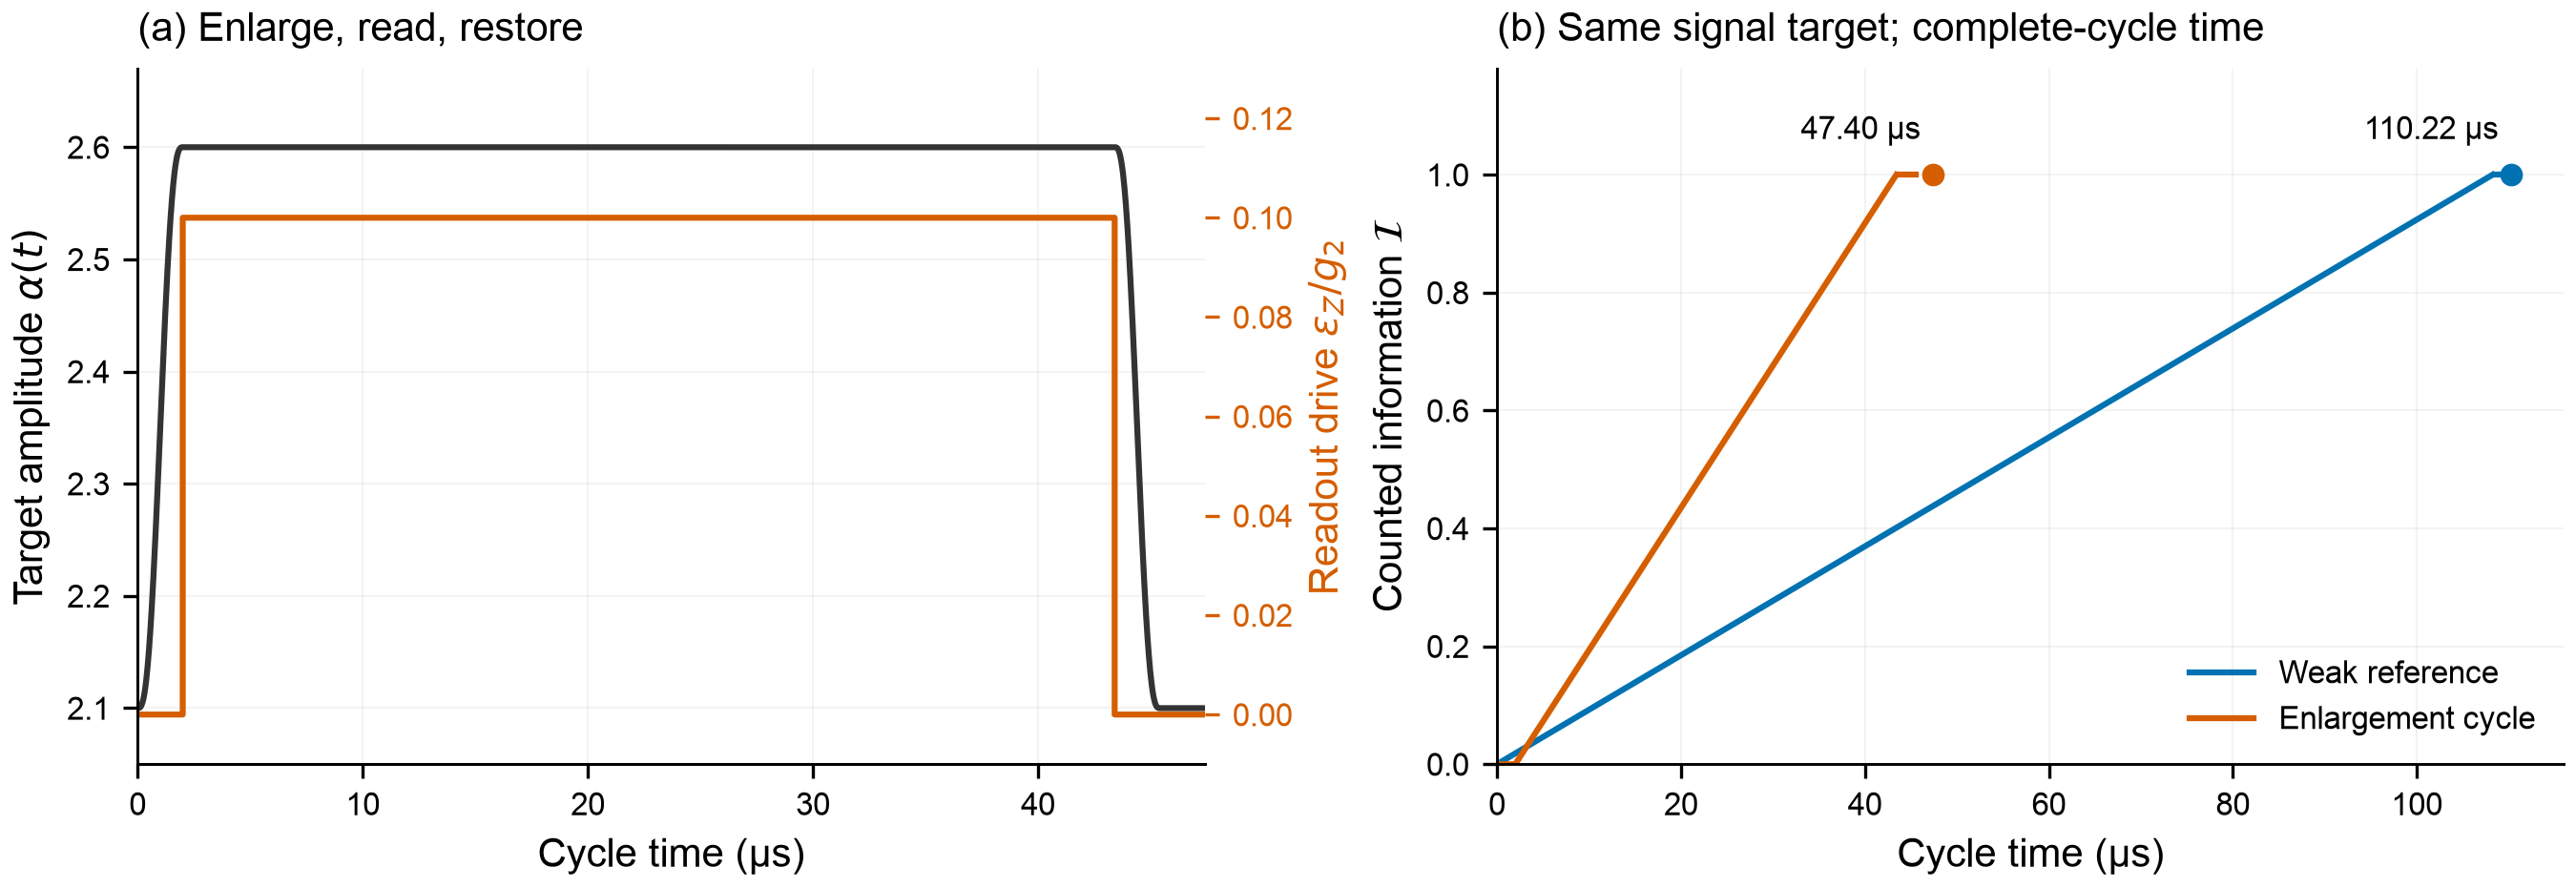

In [4]:
display(Markdown(report_section('# Task 2.4(c):', '# Task 2.4(d):')))
display(Image(filename=str(ROOT/'figures/task_2_4_protocol_summary.png'), width=900))

In [5]:
display(Markdown(report_section('# Task 2.4(d):', r'\clearpage')))
base, selected = summary['cycles']['baseline'], summary['cycles']['amplified']
assert abs(base['recomputed_information']-1) < 1e-5
assert abs(selected['recomputed_information']-1) < 1e-5
assert summary['static_selected_mode']['gamma_x_per_us'] < local['storage_reference']['gamma_x_per_us']
rows = ['| Executed complete cycle | Total µs | Information | Final wrong population |',
        '|:--|--:|--:|--:|']
for label, m in [('Weak reference', base), ('Selected enlargement', selected)]:
    rows.append(f"| {label} | {m['cycle_duration_us']:.5f} | {m['recomputed_information']:.8f} | {max(m['recomputed_wrong_population']):.8g} |")
display(Markdown('\n'.join(rows)))
print('Actual complete-cycle speedup:', summary['comparisons']['conservative_cycle_speedup'])
print('Estimated static Gamma / undriven storage:', summary['comparisons']['conservative_gamma_over_idle'])

# Task 2.4(d): explain and validate the improvement

## Complete-cycle results

We evaluate the memory in its original storage basis after recovery. The reported $p_X$ is population in the opposite logical state, without postselection; leakage is population outside the orthonormal cat code space (Appendix B). These are directly integrated final populations, not a static rate multiplied by pulse duration.

| Quantity | Weak reference | Enlargement cycle |
|:--|--:|--:|
| Information at measurement end | 1.0000000 | 0.9999925 |
| Readout interval (µs) | 108.2205 | 41.3997 |
| Complete-cycle time (µs) | 110.2205 | 47.3997 |
| Final wrong-logical population $p_X$ | $3.3063\times10^{-4}$ | $7.9483\times10^{-6}$ |
| Final code-space leakage | $8.110\times10^{-6}$ | $8.110\times10^{-6}$ |

The enlargement cycle is **2.33 times faster at the same calculated signal target**, with a smaller recovered wrong-state population. This comparison includes its extra control time and tests whether the benefit survives return to the original cat size.

## Why it works, and whether protection survives

Doubling $\epsilon_Z$ while increasing $\alpha$ from 2.1 to 2.6 predicts a field gain $2(2.1/2.6)=1.615$. The quantum value is 1.616, and the information accumulation rate increases by 2.61. After both ramps and the common 2-µs recovery are included, the complete-cycle speed gain is 2.33.

The separate static-rate test gives $\Gamma_X=2.0351\times10^{-7}\,\mathrm{µs}^{-1}$ on the enlarged readout plateau, compared with $3.8475\times10^{-7}$ for original undriven storage. The readout value is **0.529 times storage**, meeting the stated protection criterion. That rate test describes the plateau; the complete-cycle population test above also includes switching transients, the ramps and recovery. A separate equal-duration idle comparison is retained in Appendix B.

## What the evidence supports

The observed gains exceed the tested cutoff changes. The last cycle-cutoff increment changes $p_X$ by 0.775%; the last separate memory and buffer increments change the estimated static rate by 0.699% and 0.530%, with an earlier joint increment of 2.117%. These are empirical convergence checks, not rigorous error bars. Appendix B gives the full cutoff and independent-solver evidence.

The result is a demonstrated improvement over the specified weak reference **within the ideal cubic two-mode model**. It is not a global optimum over all controls. The circuit corrections in Appendix A have separate static and short-time checks, but the complete enlargement cycle has not been validated with them. Actual single-shot fidelity also remains untested. Additional pulse studies are supporting material in Appendix C.

| Executed complete cycle | Total µs | Information | Final wrong population |
|:--|--:|--:|--:|
| Weak reference | 110.22051 | 1.00000000 | 0.00033062567 |
| Selected enlargement | 47.39966 | 0.99999246 | 7.9483413e-06 |

Actual complete-cycle speedup: 2.3253439958293867
Estimated static Gamma / undriven storage: 0.5289468404235262


## Supporting validation

The supplied(a-b) reference informed the clearer derivation, but its unverified numerical tables were not imported. The algebra and coherent-output normalization checks below are independent of the simulation Hamiltonian builders. The four pulse checks remain supporting evidence; they do not validate an unexecuted hybrid or the complete enlarged cycle with circuit corrections.

Laboratory drive-phase coefficient error: 1.962615573354719e-17
Fifth-order RWA matrix error /µs: 8.583756213050954e-13
Emitted coherent-state coherence-decay exponent: 0.25920000000002386
independent_validation pulse_b1f2b1393d0b0ff1 PASS
independent_validation pulse_6f787216b4e21a6d PASS
supplemental_cutoffs pulse_b1f2b1393d0b0ff1 PASS
supplemental_cutoffs pulse_6f787216b4e21a6d PASS


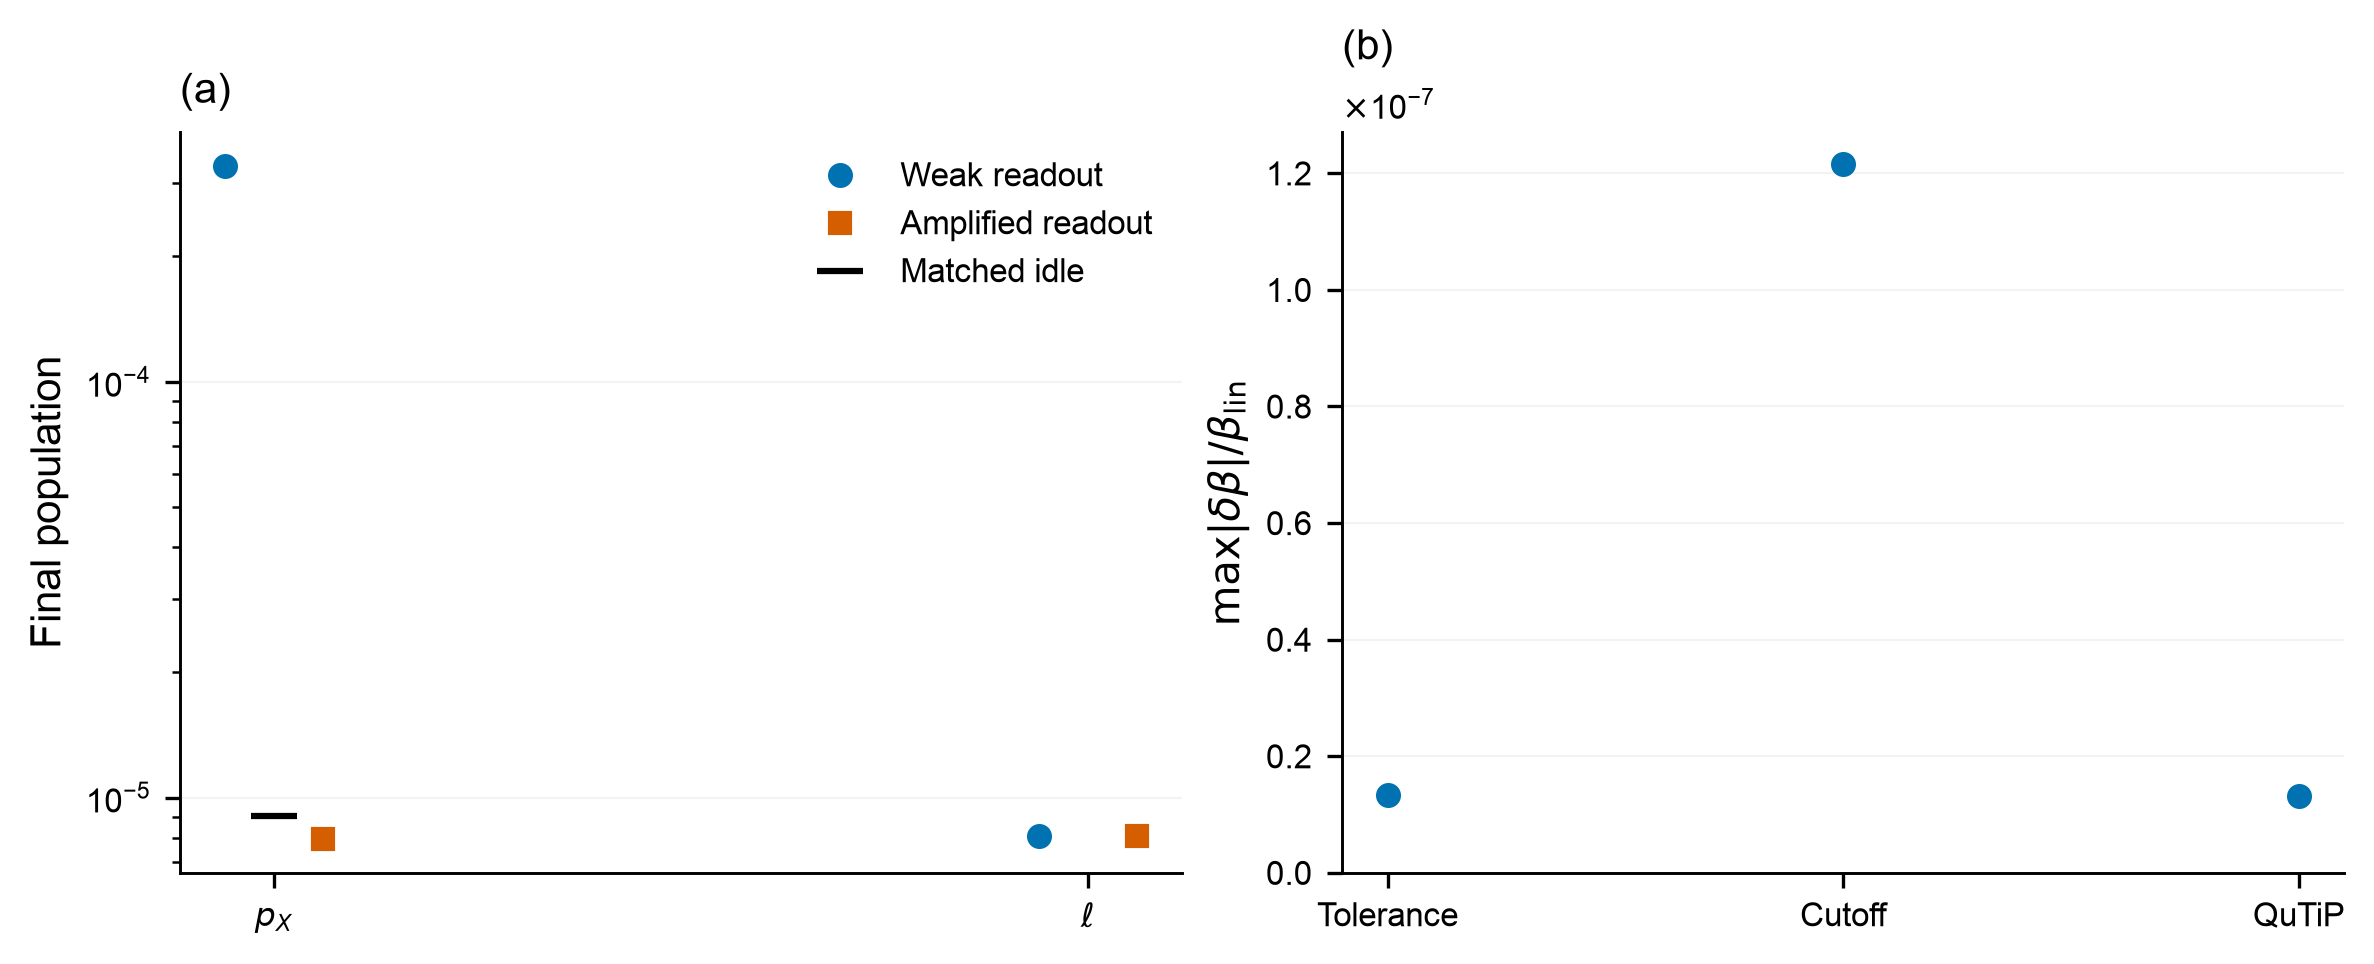

Complete corrected-circuit enlargement-cycle validation remains open.


In [6]:
checks = summary['independent_reference_checks']
assert checks['all_checks_pass']
print('Laboratory drive-phase coefficient error:', checks['creation_coefficient_error'])
print('Fifth-order RWA matrix error /µs:', checks['fifth_order_rwa_low_fock_max_error_per_us'])
print('Emitted coherent-state coherence-decay exponent:', checks['coherent_output_decay_exponent_per_us'])
for check in summary['campaign']['independent_and_supplemental_checks']:
    assert check['validation_passed']
    print(check['kind'], Path(check['source']).stem, 'PASS')
display(Image(filename=str(ROOT/'figures/task_2_4_validation.png'), width=900))
print('Complete corrected-circuit enlargement-cycle validation remains open.')

## Files and disclosure

`docs/task_2_4_final.md` is the canonical report source. Its appendices retain complete logical-state definitions, measurement convention, cutoff checks, circuit sensitivity, optional controls and negative findings. `docs/task_2_4_README.md` links the final PDF, original detailed notebook 09, code, results and reproduction instructions. The evidence index preserves input SHA256 hashes and original execution identities.

AI assisted with derivation, implementation, execution, checks and editing. The submitting team remains responsible for explaining and defending the results. No experimental or human scientific approval is implied.